# **AI METHODS I**
## Day IV · Notebook 2: Computer vision with OpenCV

| Notebook | Topic |
|---|---|
| 1 | Neural network fundamentals and tensors |
| **2 · this one** | Computer vision with **hand-written rules**: OpenCV |
| 3 | Computer vision that **learns**: YOLO and SAM |

In notebook 1 we saw that an image is just a tensor of numbers. **OpenCV** is the classic library for working with those numbers: resizing, filtering, finding colours, edges and shapes. It uses **rules that you write yourself**, with no training data:

```
 "find the hi-vis vests"   =   pixels whose hue is yellow-green, very saturated and very bright
                               → clean the mask → keep blobs bigger than 120 pixels → draw boxes
```

| Strengths of rule-based vision | Weaknesses |
|---|---|
| No training data, no GPU | Rules break when light, angle or background change |
| Fast: runs on any laptop, in real time | Every new object needs new hand-tuned rules |
| Explainable: you know exactly why a pixel was selected | Hard to describe complex objects ("a helmet") as rules |

It is still everywhere in practice: measuring and inspection, plan and document processing, perspective correction, privacy filters, and as **preprocessing** for deep learning. In built-environment work you will use it to rectify facade photos, count elements, clean up scans and prepare datasets.

### Learning goals
By the end of this notebook you will be able to:
1. Load, display, transform and crop images, and explain why OpenCV uses **BGR**.
2. Use **thresholds**, **edges** and **filters**, and explain filtering as a **convolution**.
3. Detect objects by **colour** in the HSV space, clean the result with **morphology**, then count and box objects with **contours**.
4. **Rectify** a facade photo with a perspective transform and find its windows with rules.
5. Find a known object with **SIFT** feature matching, and **anonymise faces** with a Haar cascade.
6. Build a **video pipeline**, and recognise the **limits** of rule-based vision.

### Table of contents
0. Setup and images
1. An image is an array
2. Thresholds and edges
3. Filtering = convolution
4. Colour detection and counting: hi-vis vests
5. Facades: perspective correction and windows
6. Finding a known object: SIFT feature matching
7. Privacy: anonymising faces
8. A video pipeline
9. The limits of rules
10. Summary
11. Your turn
12. Conclusions and next steps

# 0. Setup and images

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install opencv-python numpy matplotlib requests

In [2]:
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

In [3]:
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
for folder in [DATA_DIR, FIG_DIR]:
    folder.mkdir(exist_ok=True)

%config InlineBackend.figure_formats = ["jpeg"]   # photos as JPEG: a much smaller notebook file
plt.rcParams["figure.figsize"] = (10, 6)
RANDOM_STATE = 42
print("OpenCV", cv2.__version__)


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")


def show_image(image, title=None, ax=None):
    # Show an OpenCV image (BGR colour or grayscale) with matplotlib (which expects RGB)
    ax = ax or plt.gca()
    if image.ndim == 3:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(image, cmap="gray")
    ax.set_axis_off()
    if title:
        ax.set_title(title)


def show_row(images, titles, name=None, height=4.5):
    # Several images side by side
    fig, axes = plt.subplots(1, len(images), figsize=(height * 1.45 * len(images), height))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        show_image(image, title, ax)
    plt.tight_layout()
    if name:
        save_fig(name)
    plt.show()

OpenCV 4.14.0


## Our images

All images are **openly licensed** and downloaded once into `data/`. Credit them whenever you reuse them.

| File | What | Author, licence |
|---|---|---|
| `facade_berlin.jpg` | Apartment building, Oranienstraße 165A, Berlin-Kreuzberg | Jörg Zägel, [CC BY-SA 3.0](https://commons.wikimedia.org/wiki/File:Berlin,_Kreuzberg,_Oranienstrasse_165A,_Mietshaus.jpg) |
| `facade_milan.jpg` | Apartment building near the Duomo, Milan | sagesolar, [CC BY 4.0](https://commons.wikimedia.org/wiki/File:Apartment_building_near_the_Duomo_in_Milan.jpg) |
| `site_visit.jpg` | Site visit, naval hospital construction site | NAVFAC, [CC BY 2.0](https://commons.wikimedia.org/wiki/File:Navy_Surgeon_General_Takes_a_Tour_on_New_Naval_Hospital_Construction_Site_(8117042191).jpg) |
| `site_video.webm` | Building construction, Moira Close, Haringey, London (2025), 5.5 min, 480p | Acabashi, [CC BY-SA 4.0](https://commons.wikimedia.org/wiki/File:Building_construction_Moira_Close_Broadwater_Farm_Haringey_2025_21.webm) |
| `face_detection_yunet.onnx` | A small learned face detector (section 7) | [OpenCV Zoo](https://github.com/opencv/opencv_zoo/tree/main/models/face_detection_yunet), MIT licence |

In [4]:
COMMONS = "https://upload.wikimedia.org/wikipedia/commons"
DOWNLOADS = {
    "facade_berlin.jpg": f"{COMMONS}/thumb/a/a5/Berlin%2C_Kreuzberg%2C_Oranienstrasse_165A%2C_Mietshaus.jpg/1920px-Berlin%2C_Kreuzberg%2C_Oranienstrasse_165A%2C_Mietshaus.jpg",
    "facade_milan.jpg": f"{COMMONS}/thumb/a/a2/Apartment_building_near_the_Duomo_in_Milan.jpg/1920px-Apartment_building_near_the_Duomo_in_Milan.jpg",
    "site_visit.jpg": f"{COMMONS}/1/1f/Navy_Surgeon_General_Takes_a_Tour_on_New_Naval_Hospital_Construction_Site_%288117042191%29.jpg",
    "face_detection_yunet.onnx": "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
    "site_video.webm": f"{COMMONS}/transcoded/a/ab/Building_construction_Moira_Close_Broadwater_Farm_Haringey_2025_21.webm/Building_construction_Moira_Close_Broadwater_Farm_Haringey_2025_21.webm.480p.vp9.webm",
}

for filename, url in DOWNLOADS.items():
    path = DATA_DIR / filename
    if not path.exists():
        # Wikimedia asks every program to identify itself with a User-Agent
        response = requests.get(url, headers={"User-Agent": "IAAC-AI-Methods-course/1.0 (educational use)"}, timeout=300)
        response.raise_for_status()
        path.write_bytes(response.content)
    print(f"{filename:>26}: {path.stat().st_size / 1e6:5.1f} MB")

berlin = cv2.imread(str(DATA_DIR / "facade_berlin.jpg"))
milan = cv2.imread(str(DATA_DIR / "facade_milan.jpg"))
site_visit = cv2.imread(str(DATA_DIR / "site_visit.jpg"))

         facade_berlin.jpg:   0.7 MB
          facade_milan.jpg:   1.0 MB
            site_visit.jpg:   1.6 MB
 face_detection_yunet.onnx:   0.2 MB
           site_video.webm:  45.4 MB


The video is long, so we read only the frames we need. `read_frame` jumps to a given second:

Video: 854 x 480 pixels, 29.97 frames per second, 9,990 frames = 5.6 minutes
Figure saved to figures/nb2_01_video_frames.png


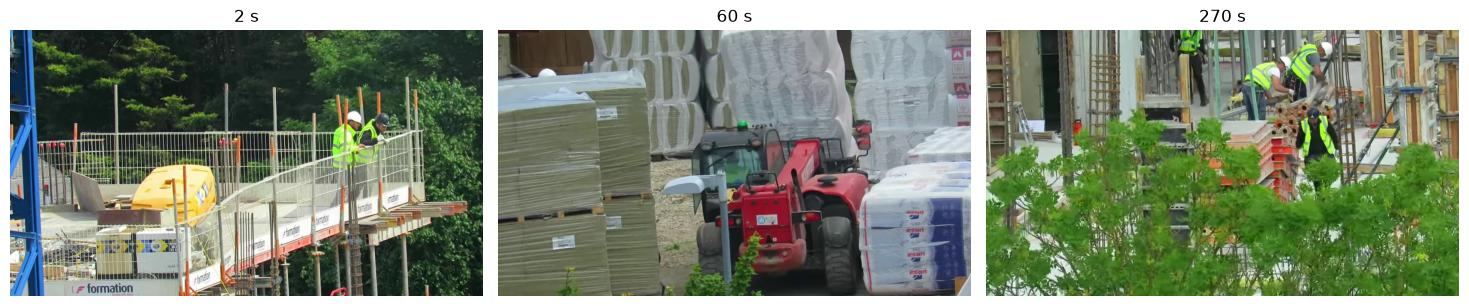

In [5]:
VIDEO_PATH = DATA_DIR / "site_video.webm"


def read_frame(seconds):
    # Read the video frame at a given time (in seconds)
    capture = cv2.VideoCapture(str(VIDEO_PATH))
    capture.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    ok, frame = capture.read()
    capture.release()
    if not ok:
        raise ValueError(f"Could not read a frame at {seconds} s")
    return frame


capture = cv2.VideoCapture(str(VIDEO_PATH))
fps = capture.get(cv2.CAP_PROP_FPS)
n_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"Video: {int(capture.get(3))} x {int(capture.get(4))} pixels, {fps:.2f} frames per second, "
      f"{n_frames:,} frames = {n_frames / fps / 60:.1f} minutes")
capture.release()

frame_workers = read_frame(270)      # workers in hi-vis vests
frame_platform = read_frame(2)       # two workers on a platform
frame_telehandler = read_frame(60)   # a telehandler between material stacks
show_row([frame_platform, frame_telehandler, frame_workers], ["2 s", "60 s", "270 s"], "nb2_01_video_frames", height=3.4)

# 1. An image is an array

A colour image is a NumPy array of shape **height × width × 3**: one number from 0 to 255 per pixel and per colour channel.

⚠️ **Watch out:** OpenCV stores the channels in the order **Blue, Green, Red (BGR)**, not RGB. This is a historical choice (it was the common camera format when OpenCV was born). Matplotlib, PIL and PyTorch expect RGB, so convert with `cv2.cvtColor(image, cv2.COLOR_BGR2RGB)` before showing or passing an image to them. Our `show_image()` helper does it for you.

shape: (1541, 1920, 3)  dtype: uint8  min/max: 0 255
Pixel at row 400, column 800 (B, G, R): [176 208 243]


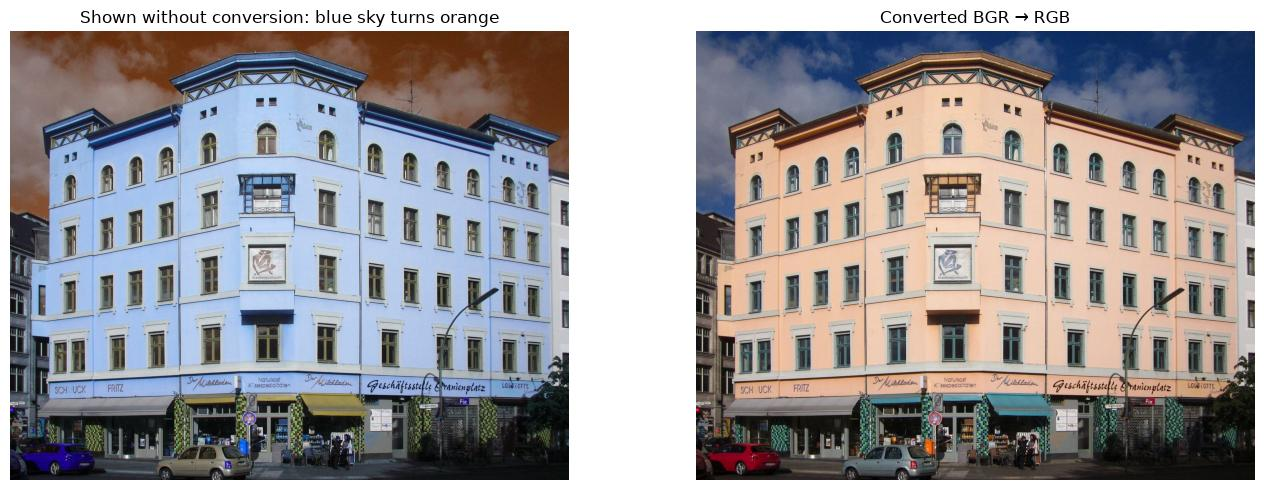

In [6]:
print("shape:", berlin.shape, " dtype:", berlin.dtype, " min/max:", berlin.min(), berlin.max())
print("Pixel at row 400, column 800 (B, G, R):", berlin[400, 800])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(berlin)                                  # wrong: BGR shown as RGB
axes[0].set_title("Shown without conversion: blue sky turns orange")
axes[0].set_axis_off()
show_image(berlin, "Converted BGR → RGB", axes[1])
plt.tight_layout()
plt.show()

## 1.1 Basic transformations

Resizing, rotating, translating and cropping are array operations. Cropping is just **slicing**: `image[rows, columns]`.

     small: (385, 480, 3)
   rotated: (1920, 1541, 3)
translated: (1541, 1920, 3)
      crop: (520, 360, 3)
Figure saved to figures/nb2_02_transformations.png


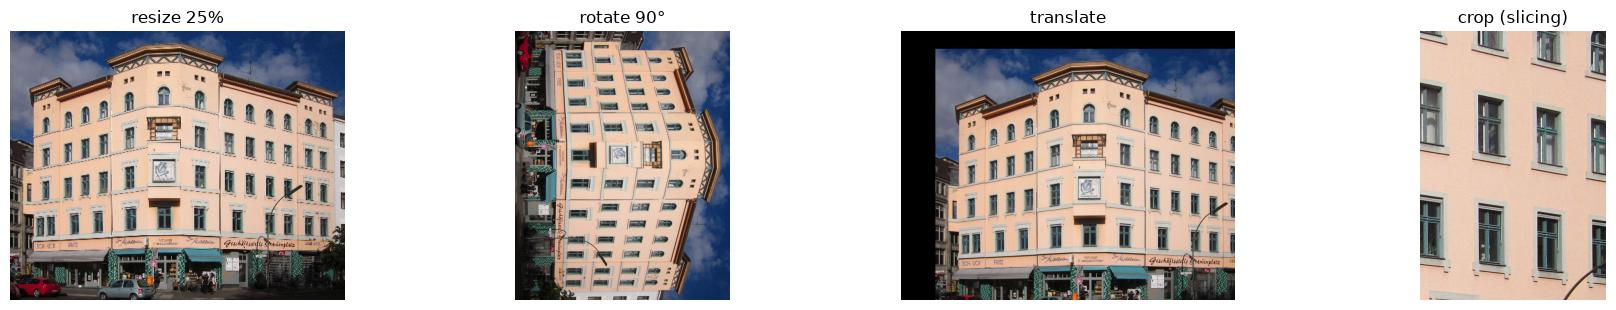

In [7]:
height, width = berlin.shape[:2]

small = cv2.resize(berlin, None, fx=0.25, fy=0.25)                    # 25% of the size
rotated = cv2.rotate(berlin, cv2.ROTATE_90_CLOCKWISE)
shift = np.float32([[1, 0, 200], [0, 1, 100]])                         # move 200 px right, 100 px down
translated = cv2.warpAffine(berlin, shift, (width, height))
crop = berlin[480:1000, 1240:1600]                                     # rows 480-1000, columns 1240-1600

for name, image in [("small", small), ("rotated", rotated), ("translated", translated), ("crop", crop)]:
    print(f"{name:>10}: {image.shape}")
show_row([small, rotated, translated, crop], ["resize 25%", "rotate 90°", "translate", "crop (slicing)"],
         "nb2_02_transformations", height=3.2)

## 1.2 Channels and histograms

Each channel can be looked at on its own as a grayscale image. The **histogram** counts how many pixels have each brightness value: it shows whether a photo is dark, bright, low-contrast or well exposed.

Figure saved to figures/nb2_03_channels.png


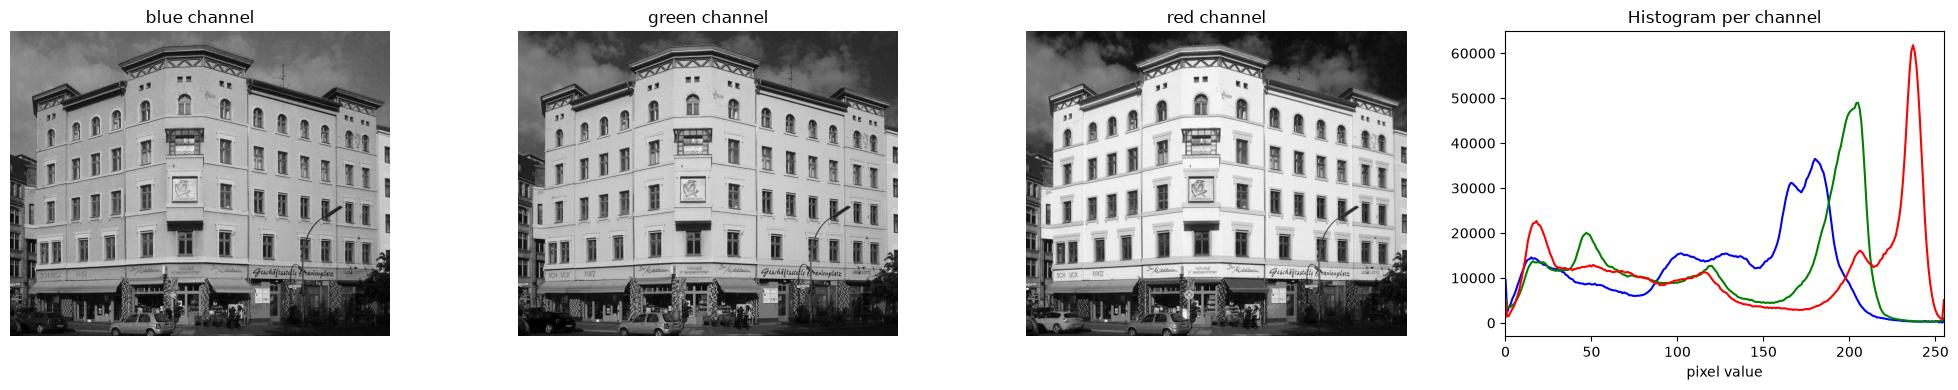

In [8]:
blue, green, red = cv2.split(berlin)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, channel, name in zip(axes[:3], [blue, green, red], ["blue", "green", "red"]):
    show_image(channel, f"{name} channel", ax)
for channel, color in zip([blue, green, red], ["blue", "green", "red"]):
    histogram = cv2.calcHist([channel], [0], None, [256], [0, 256])
    axes[3].plot(histogram, color=color)
axes[3].set_xlim(0, 255)
axes[3].set_title("Histogram per channel")
axes[3].set_xlabel("pixel value")
plt.tight_layout()
save_fig("nb2_03_channels")
plt.show()

The sky is bright in the **blue** channel and dark in the **red** one; the pink plaster is bright in **red**. Each channel is a different "view" of the scene, and choosing the right one is often the first step of a rule.

## 1.3 Histogram equalisation: fixing a dark photo

Site photos are often taken against the light. Here we **simulate** an underexposed photo by darkening a video frame, then **equalise** its histogram: the brightness values are spread over the whole 0–255 range.

Figure saved to figures/nb2_04_equalisation.png


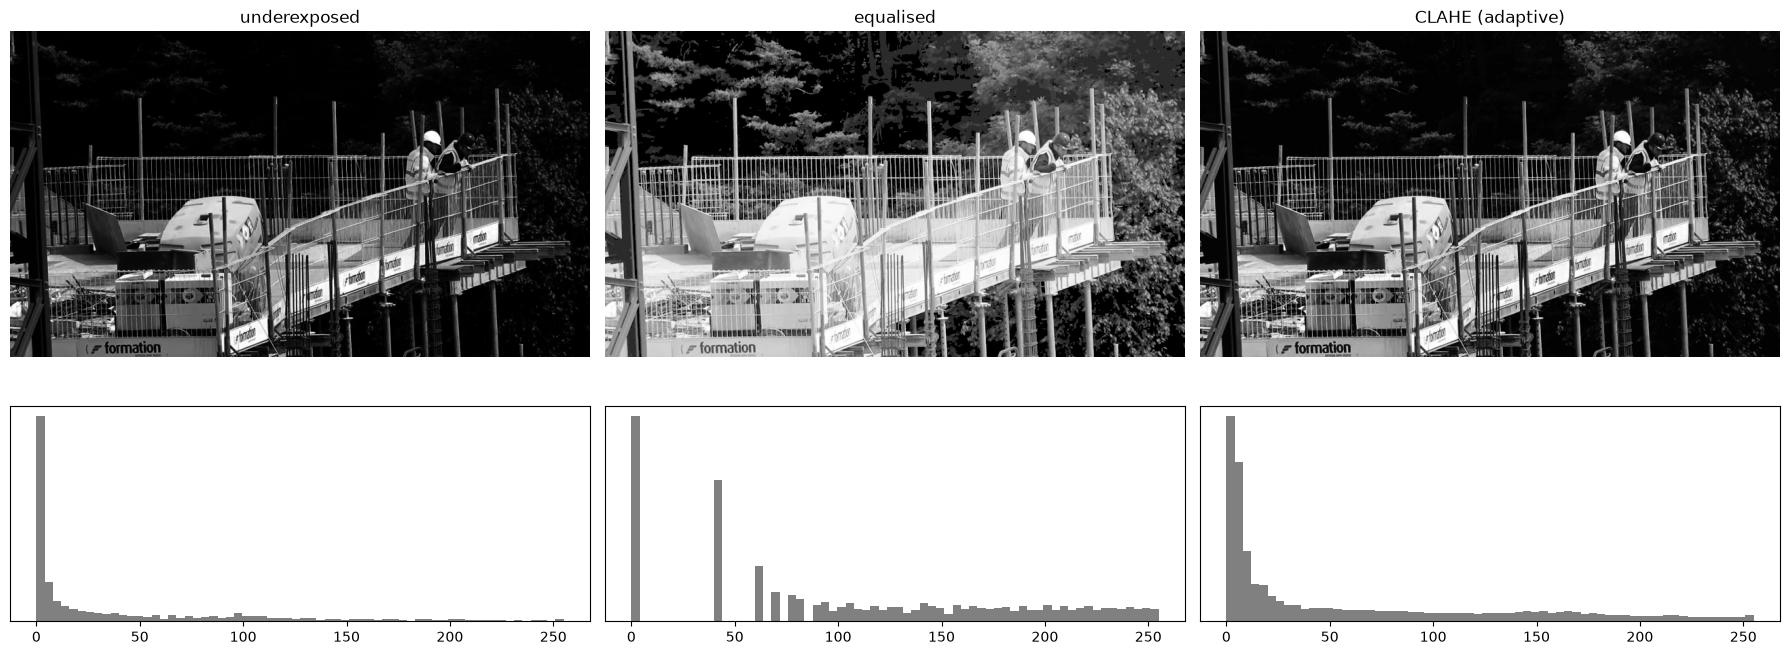

In [9]:
gray = cv2.cvtColor(frame_platform, cv2.COLOR_BGR2GRAY)
dark = (255 * (gray / 255) ** 2.8).astype(np.uint8)        # simulate underexposure (a gamma curve)
equalized = cv2.equalizeHist(dark)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(dark)   # adaptive version: equalises region by region

fig, axes = plt.subplots(2, 3, figsize=(18, 7.5), gridspec_kw={"height_ratios": [3, 1.2]})
for col, (image, title) in enumerate([(dark, "underexposed"), (equalized, "equalised"), (clahe, "CLAHE (adaptive)")]):
    show_image(image, title, axes[0, col])
    axes[1, col].hist(image.ravel(), bins=64, range=(0, 255), color="grey")
    axes[1, col].set_yticks([])
plt.tight_layout()
save_fig("nb2_04_equalisation")
plt.show()

Equalisation stretches the narrow, dark histogram over the full range. **CLAHE** (*contrast-limited adaptive histogram equalisation*) does it tile by tile and limits the boost, so it brings out detail without exaggerating noise or the bright sky. It is a common preprocessing step before detection.

# 2. Thresholds and edges

## 2.1 Thresholding: from gray to black-and-white

A **threshold** turns a grayscale image into a **binary mask**: every pixel brighter than a value becomes white (255), everything else black (0). Masks are the raw material of most rule-based detection.

| Method | How the threshold is chosen |
|---|---|
| **Global** | You choose one value (e.g. 127) for the whole image |
| **Otsu** | OpenCV chooses the value that best separates the histogram into two groups |
| **Adaptive** | A different value for every neighbourhood, from its local average: copes with uneven light and shadows |

The Milan facade is a good test: dark windows on a bright, cracked, unevenly lit wall.

Otsu chose a threshold of 105
Figure saved to figures/nb2_05_thresholds.png


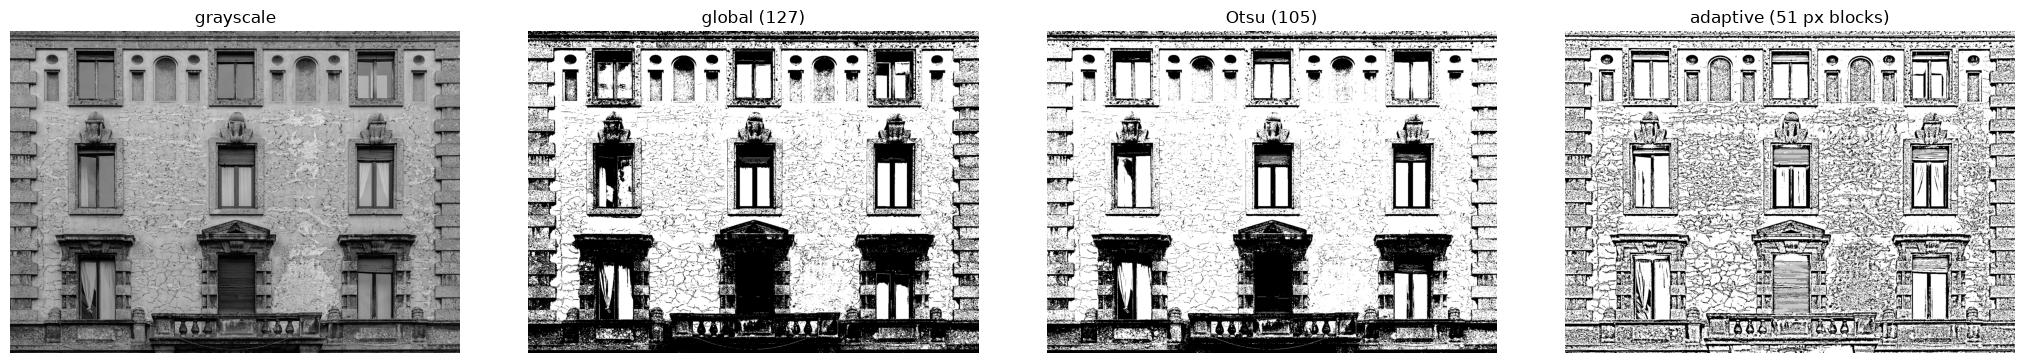

In [10]:
milan_gray = cv2.cvtColor(milan, cv2.COLOR_BGR2GRAY)

_, global_127 = cv2.threshold(milan_gray, 127, 255, cv2.THRESH_BINARY)
otsu_value, otsu = cv2.threshold(milan_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(milan_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 10)

print(f"Otsu chose a threshold of {otsu_value:.0f}")
show_row([milan_gray, global_127, otsu, adaptive],
         ["grayscale", "global (127)", f"Otsu ({otsu_value:.0f})", "adaptive (51 px blocks)"], "nb2_05_thresholds", height=3.6)

🤔 **Think about it:** what does each threshold do well? The global and Otsu thresholds split the image into "dark things" (windows, shutters, the stone frames) and "light things" (the wall), which is what we want for finding windows. The adaptive threshold ignores the overall brightness and highlights **local** contrast: the cracks in the plaster, the window bars and the stone joints. That makes it the right choice for **scanned drawings and documents** with uneven lighting, and for spotting **surface defects** such as cracks.

## 2.2 Edges: where the brightness changes

An **edge** is a place where the brightness changes sharply. The **Canny** detector finds thin, connected edges in two steps: it measures how strongly the brightness changes (the gradient), then keeps pixels above a high threshold and the ones connected to them above a low threshold.

Figure saved to figures/nb2_06_edges.png


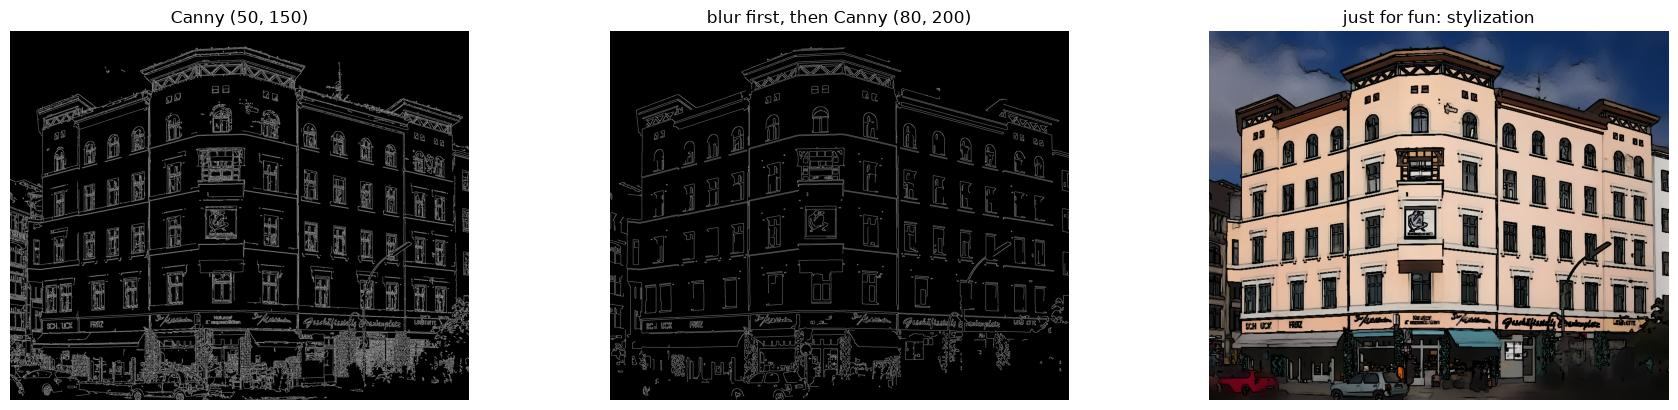

In [11]:
berlin_gray = cv2.cvtColor(berlin, cv2.COLOR_BGR2GRAY)
edges_fine = cv2.Canny(berlin_gray, 50, 150)
edges_coarse = cv2.Canny(cv2.GaussianBlur(berlin_gray, (7, 7), 0), 80, 200)
cartoon = cv2.stylization(cv2.resize(berlin, None, fx=0.5, fy=0.5), sigma_s=60, sigma_r=0.45)

show_row([edges_fine, edges_coarse, cartoon], ["Canny (50, 150)", "blur first, then Canny (80, 200)", "just for fun: stylization"],
         "nb2_06_edges", height=4.2)

Blurring before Canny removes the small texture edges and keeps the **architectural lines**: window frames, cornices, floor slabs. Edge maps are used to find lines and vanishing points, to compare a photo with a drawing, and as input to contour detection.

🤔 **Think about it:** where could edge detection be used in your projects? For instance: measuring the outline of a building from a drone photo, finding cracks, aligning a site photo with a BIM view, or vectorising a scanned plan.

# 3. Filtering = convolution

Blur, sharpen and edge detection are all **convolutions**: a small grid of numbers (a **kernel**) slides over the image, and every output pixel is the weighted sum of the input pixels under the kernel.

```
   input pixels          kernel (3 x 3)          output pixel
   10  10  10           1/9  1/9  1/9
   10  90  10     x     1/9  1/9  1/9     =   (10·8 + 90) / 9  ≈  19
   10  10  10           1/9  1/9  1/9          (the bright speck is averaged away)
```

This idea is **exactly** what a convolutional neural network does in notebook 3, with one difference: there, the numbers in the kernels are **learned** from data instead of chosen by hand.

Figure saved to figures/nb2_07_convolution.png


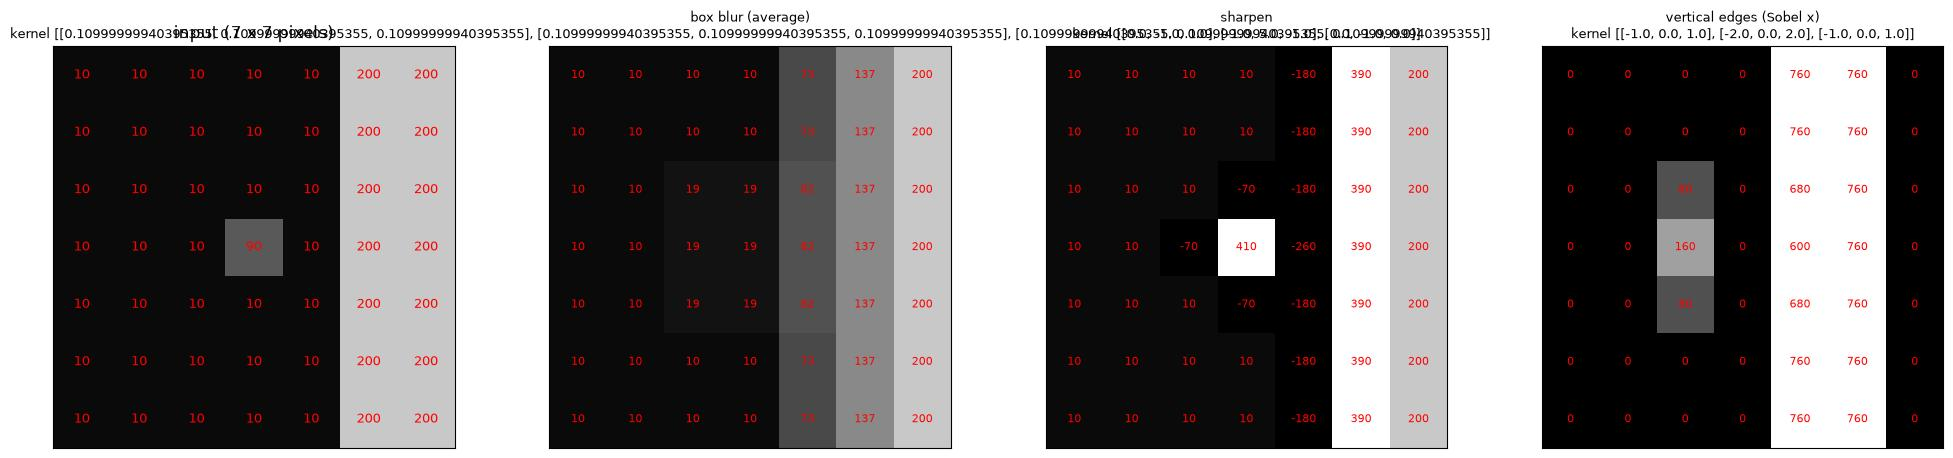

In [12]:
tiny = np.full((7, 7), 10, dtype=np.float32)
tiny[3, 3] = 90                              # one bright speck (noise)
tiny[:, 5:] = 200                            # a bright region on the right: an edge

kernels = {
    "box blur (average)": np.full((3, 3), 1 / 9, dtype=np.float32),
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32),
    "vertical edges (Sobel x)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32),
}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
axes[0].imshow(tiny, cmap="gray", vmin=0, vmax=255)
for (r, c), v in np.ndenumerate(tiny):
    axes[0].text(c, r, f"{v:.0f}", ha="center", va="center", color="red", fontsize=9)
axes[0].set_title("input (7 x 7 pixels)")
for ax, (name, kernel) in zip(axes[1:], kernels.items()):
    result = cv2.filter2D(tiny, -1, kernel, borderType=cv2.BORDER_REPLICATE)
    ax.imshow(np.clip(result, 0, 255), cmap="gray", vmin=0, vmax=255)
    for (r, c), v in np.ndenumerate(result):
        ax.text(c, r, f"{v:.0f}", ha="center", va="center", color="red", fontsize=8)
    ax.set_title(f"{name}\nkernel {kernel.round(2).tolist()}", fontsize=9)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
save_fig("nb2_07_convolution")
plt.show()

- The **box blur** spreads the bright speck (90 → about 19 in the middle) and softens the edge.
- **Sharpen** makes the speck *stronger* and exaggerates the edge.
- The **vertical-edge** kernel outputs 0 on flat areas and a large value only where the brightness changes from left to right: it "detects" the edge.

## 3.1 Three smoothing filters

Real photos contain noise. Let's add **salt-and-pepper** noise (random black and white pixels, like dust on a scan or a faulty sensor) and compare three filters:

| Filter | How it works | Good at |
|---|---|---|
| **Gaussian** | Weighted average, more weight to the centre | General smoothing, before edge detection |
| **Median** | Takes the **median** of the neighbourhood instead of the average | Removing isolated black/white pixels (salt and pepper) |
| **Bilateral** | Averages only neighbours that are close **and** have a similar colour | Smoothing surfaces while **keeping edges sharp** |

Figure saved to figures/nb2_08_filters.png


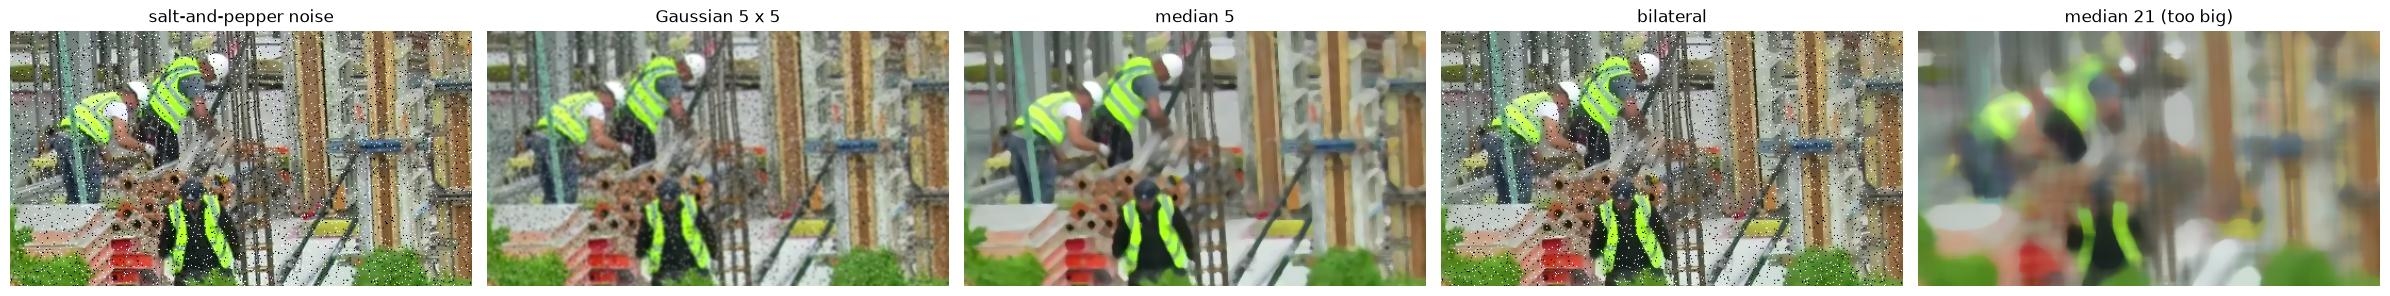

In [13]:
crop_workers = frame_workers[0:240, 420:854].copy()
noisy = crop_workers.copy()
rng = np.random.default_rng(RANDOM_STATE)
mask = rng.random(noisy.shape[:2])
noisy[mask < 0.03] = 0          # 3% "pepper"
noisy[mask > 0.97] = 255        # 3% "salt"

gaussian = cv2.GaussianBlur(noisy, (5, 5), 0)
median = cv2.medianBlur(noisy, 5)
bilateral = cv2.bilateralFilter(noisy, 9, 75, 75)
median_too_big = cv2.medianBlur(noisy, 21)

fig, axes = plt.subplots(1, 5, figsize=(24, 3.9))
for ax, image, title in zip(axes, [noisy, gaussian, median, bilateral, median_too_big],
                            ["salt-and-pepper noise", "Gaussian 5 x 5", "median 5", "bilateral", "median 21 (too big)"]):
    show_image(image, title, ax)
plt.tight_layout()
save_fig("nb2_08_filters")
plt.show()

🤔 **Think about it:**
- **Which filter removes this noise best, and why?** The **median**: a white or black speck is an extreme value, and the median simply ignores it, while averages (Gaussian, bilateral) smear it into a grey blob.
- **What happens when the median kernel is too large?** Every pixel takes the value of a large neighbourhood: thin elements (the reinforcement bars, the vest stripes) disappear and the image looks painted.
- **We want colours as pure as possible, without losing the borders between objects. Which filter?** The **bilateral** filter: it averages within a colour region but not across edges, which is why it is a good step before colour detection on clean images.

# 4. Colour detection and counting: hi-vis vests

## 4.1 The HSV colour space

RGB mixes colour and brightness together: a yellow vest in the shade and in the sun have very different R, G and B values. **HSV** separates them:

| Channel | Meaning | Range in OpenCV |
|---|---|---|
| **H**ue | *Which* colour (red, yellow, green, blue…), as an angle on the colour wheel | **0–179** (the 0–360° wheel halved, to fit in one byte) |
| **S**aturation | How *pure* the colour is (0 = grey, 255 = vivid) | 0–255 |
| **V**alue | How *bright* it is (0 = black) | 0–255 |

To select "hi-vis yellow" we can then say: hue between 32 and 48, very saturated, very bright, whatever the exact shade.

Figure saved to figures/nb2_09_hsv_chart.png


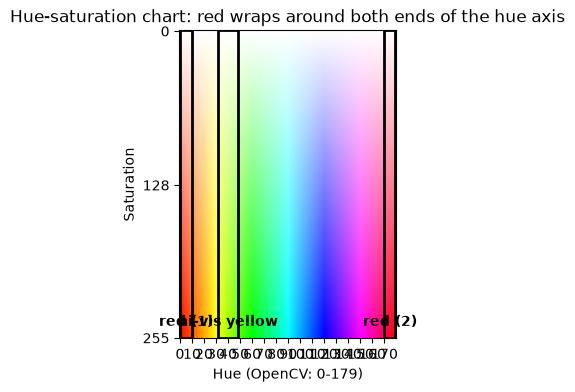

In [14]:
# A hue-saturation chart at full brightness, with OpenCV's 0-179 hue scale
hue, sat = np.meshgrid(np.arange(180), np.arange(256))
chart = cv2.cvtColor(np.dstack([hue, sat, np.full_like(hue, 255)]).astype(np.uint8), cv2.COLOR_HSV2BGR)

fig, ax = plt.subplots(figsize=(13, 4))
show_image(chart, ax=ax)
ax.set_axis_on()
ax.set_xlabel("Hue (OpenCV: 0-179)")
ax.set_ylabel("Saturation")
ax.set_xticks(range(0, 180, 10))
ax.set_yticks([0, 128, 255])
for lo, hi, label in [(32, 48, "hi-vis yellow"), (0, 10, "red (1)"), (170, 179, "red (2)")]:
    ax.axvspan(lo, hi, ymin=0, ymax=1, fill=False, edgecolor="black", lw=2)
    ax.text((lo + hi) / 2, 245, label, ha="center", fontsize=10, fontweight="bold")
ax.set_title("Hue-saturation chart: red wraps around both ends of the hue axis")
save_fig("nb2_09_hsv_chart")
plt.show()

⚠️ **Watch out:** **red** sits at **both ends** of the hue axis (around 0 and around 179). To detect red you need **two ranges** and combine the masks with a bitwise OR, as in the reference deliverable's smoke detection.

## 4.2 A colour mask

`cv2.inRange` keeps the pixels whose H, S and V are all inside the given ranges. We blur a little first (median) so that single noisy pixels do not survive.

Figure saved to figures/nb2_10_hivis_mask.png


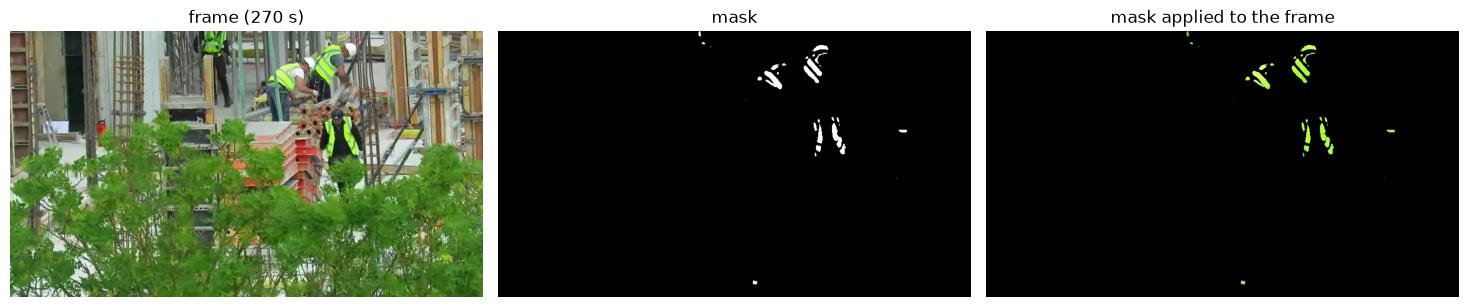

In [15]:
HIVIS_LOW = (32, 110, 200)       # hue, saturation, value
HIVIS_HIGH = (48, 255, 255)


def hivis_mask(frame):
    hsv = cv2.cvtColor(cv2.medianBlur(frame, 5), cv2.COLOR_BGR2HSV)
    return cv2.inRange(hsv, HIVIS_LOW, HIVIS_HIGH)


raw_mask = hivis_mask(frame_workers)
only_vests = cv2.bitwise_and(frame_workers, frame_workers, mask=raw_mask)
show_row([frame_workers, raw_mask, only_vests], ["frame (270 s)", "mask", "mask applied to the frame"], "nb2_10_hivis_mask", height=3.4)

## 4.3 Cleaning the mask: morphology

Masks are never clean: small specks where something happened to be yellow, holes where a reflective stripe interrupts a vest. **Morphological operations** fix this with a small structuring element (kernel):

| Operation | What it does | Use it to |
|---|---|---|
| **Erosion** | Shrinks white regions | Remove thin connections |
| **Dilation** | Grows white regions | Fill gaps |
| **Opening** = erosion then dilation | Removes small specks, keeps big blobs at their size | Delete noise **outside** objects |
| **Closing** = dilation then erosion | Fills small holes, keeps the outline | Fill holes **inside** objects |

white pixels: raw 2,692, after opening 2,521, after closing 3,295
Figure saved to figures/nb2_11_morphology.png


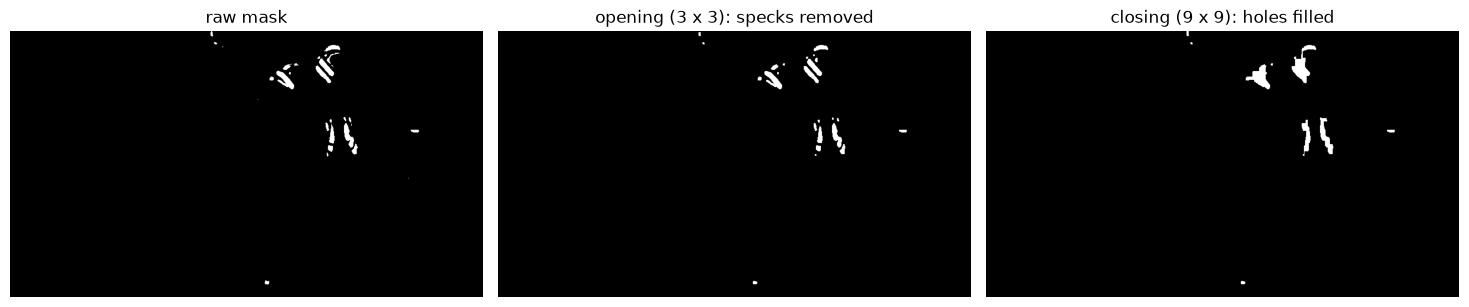

In [16]:
opened = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
cleaned = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
print(f"white pixels: raw {np.count_nonzero(raw_mask):,}, after opening {np.count_nonzero(opened):,}, "
      f"after closing {np.count_nonzero(cleaned):,}")
show_row([raw_mask, opened, cleaned], ["raw mask", "opening (3 x 3): specks removed", "closing (9 x 9): holes filled"],
         "nb2_11_morphology", height=3.4)

🤔 **Think about it:** the reflective stripes on a vest make a hole in the mask. Which operation fills it without making the vest bigger? (Closing.) And if two workers stand close together, what could closing do? (Join them into one blob: keep the kernel small.)

## 4.4 Contours: from a mask to counted objects

`cv2.findContours` traces the outline of every white blob. For each contour we can compute its **area**, its **bounding box**, and its centre from its **moments** (the centre of mass of the blob). Filtering by area removes what is too small to be a vest.

  2 s: 1 hi-vis blobs, areas [3147]
270 s: 4 hi-vis blobs, areas [429, 567, 806, 985]
300 s: 2 hi-vis blobs, areas [2267, 1003]
(at 270 s, before the area filter: 9 contours)
Figure saved to figures/nb2_12_vest_count.png


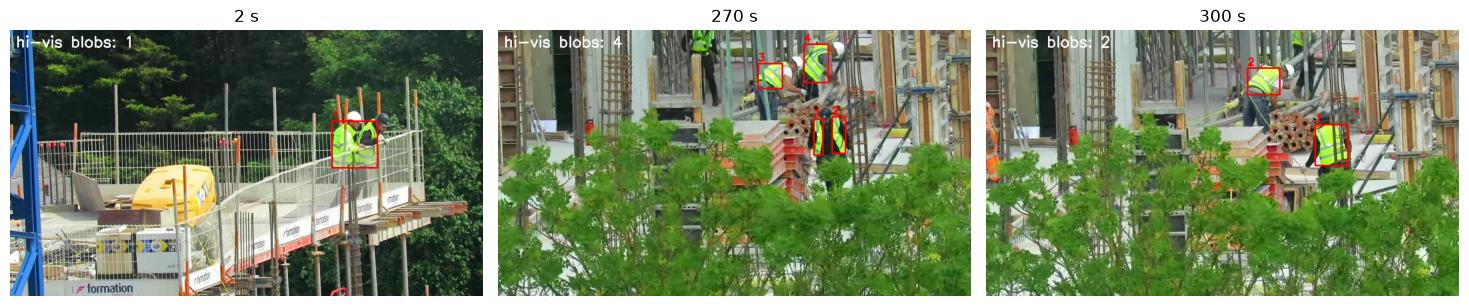

In [17]:
MIN_VEST_AREA = 120      # pixels: smaller blobs are noise


def find_vests(frame):
    mask = hivis_mask(frame)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c for c in contours if cv2.contourArea(c) > MIN_VEST_AREA]


def draw_vests(frame, vests):
    out = frame.copy()
    for number, contour in enumerate(vests, start=1):
        x, y, w, h = cv2.boundingRect(contour)                 # upright box
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 0, 255), 2)
        m = cv2.moments(contour)                               # centre of mass of the blob
        cx, cy = int(m["m10"] / m["m00"]), int(m["m01"] / m["m00"])
        cv2.circle(out, (cx, cy), 3, (255, 255, 255), -1)
        cv2.putText(out, str(number), (x, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    cv2.putText(out, f"hi-vis blobs: {len(vests)}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
    return out


all_contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
results = {t: find_vests(read_frame(t)) for t in (2, 270, 300)}
for t, vests in results.items():
    print(f"{t:>3} s: {len(vests)} hi-vis blobs, areas {[int(cv2.contourArea(c)) for c in vests]}")
print(f"(at 270 s, before the area filter: {len(all_contours)} contours)")
show_row([draw_vests(read_frame(t), v) for t, v in results.items()], [f"{t} s" for t in results], "nb2_12_vest_count", height=3.4)

The rule works, and its mistakes are typical of rule-based vision:
- **2 s:** the two workers on the platform stand shoulder to shoulder, so their vests form **one** blob: 1 counted instead of 2.
- **270 s:** 4 blobs, but they are not 4 workers: the vest of the worker at the bottom is **split in two** (its dark middle breaks the mask), and the worker cut by the top edge of the frame is **missed** (too little of his vest is visible).
- **300 s:** both yellow vests are found, but the worker in an **orange** vest on the left is invisible to a rule that only looks for yellow (exercise 1).

A count of "hi-vis blobs" is therefore **not** a count of workers. Merging, splitting and missing are exactly the problems a learned detector (notebook 3) handles better, because it learns what a *person* looks like, not just a colour.

## 4.5 Two hue ranges: detecting red

Red machinery, red fire extinguishers, red barriers: red sits at both ends of the hue axis, so we combine two masks. Here, the red telehandler at 60 s. `cv2.minAreaRect` gives a **rotated** box that fits the shape tighter than the upright `boundingRect`.

Red pixels: 915 near 0 + 15,559 near 179; largest red blob: 16,495 px
Figure saved to figures/nb2_13_red_two_ranges.png


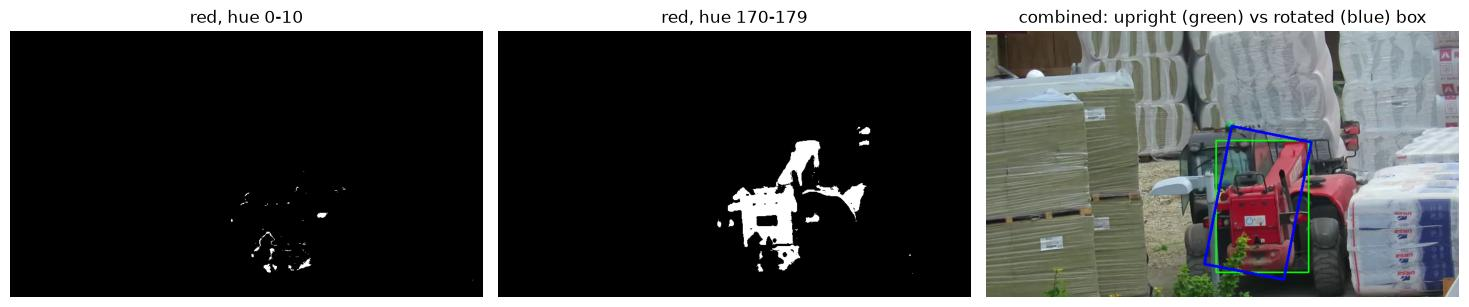

In [18]:
hsv = cv2.cvtColor(cv2.medianBlur(frame_telehandler, 5), cv2.COLOR_BGR2HSV)
red_low = cv2.inRange(hsv, (0, 120, 70), (10, 255, 255))       # red near hue 0
red_high = cv2.inRange(hsv, (170, 120, 70), (179, 255, 255))   # red near hue 179
red = cv2.bitwise_or(red_low, red_high)
red = cv2.morphologyEx(red, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
red = cv2.morphologyEx(red, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))

contours, _ = cv2.findContours(red, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
biggest = max(contours, key=cv2.contourArea)
out = frame_telehandler.copy()
x, y, w, h = cv2.boundingRect(biggest)
cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)                         # upright box (green)
rotated_box = cv2.boxPoints(cv2.minAreaRect(biggest)).astype(np.int32)
cv2.drawContours(out, [rotated_box], 0, (255, 0, 0), 3)                            # rotated box (blue)
print(f"Red pixels: {np.count_nonzero(red_low):,} near 0 + {np.count_nonzero(red_high):,} near 179; "
      f"largest red blob: {cv2.contourArea(biggest):,.0f} px")
show_row([red_low, red_high, out], ["red, hue 0-10", "red, hue 170-179", "combined: upright (green) vs rotated (blue) box"],
         "nb2_13_red_two_ranges", height=3.4)

# 5. Facades: perspective correction and windows

## 5.1 Rectifying a facade

A photo taken from the street shows a facade **in perspective**: parallel lines converge, and rectangles become trapezoids. If we know four points that form a rectangle on the real facade, a **perspective transform** (a *homography*) maps them back to a rectangle: the photo becomes an approximate **elevation**, where the windows are rectangles again and can be measured.

We pick the four corners of the right-hand wing of the Berlin building (top and bottom of its two outer edges).

Homography matrix:
 [[ 1.048000e+00  0.000000e+00 -1.261424e+03]
 [-1.850000e-01  9.270000e-01 -1.594900e+01]
 [-0.000000e+00 -0.000000e+00  1.000000e+00]]
Figure saved to figures/nb2_14_rectified.png


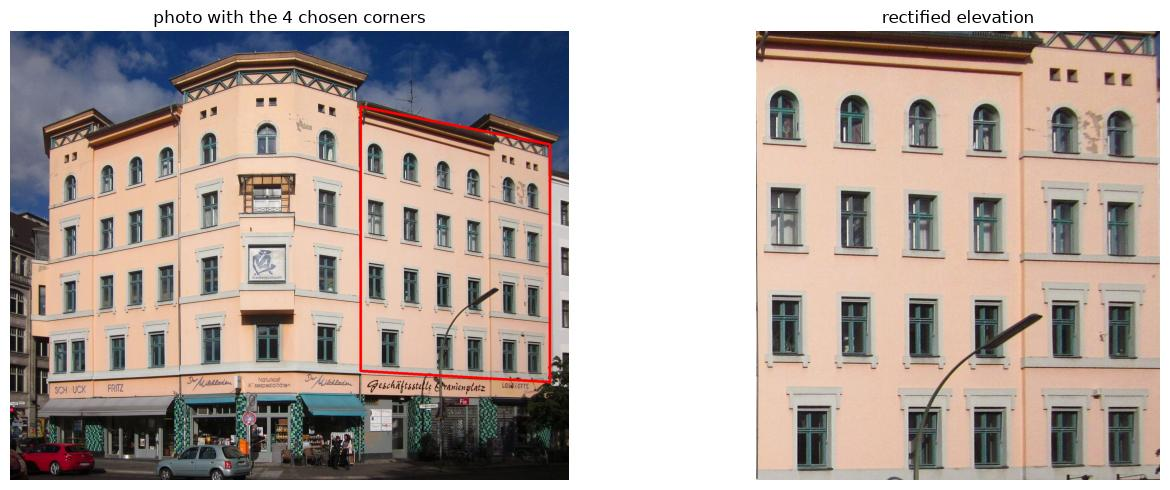

In [19]:
# Four corners of the right wing on the photo (pixels, clockwise from top-left)
corners_photo = np.float32([(1204, 258), (1854, 388), (1854, 1204), (1204, 1166)])
ELEVATION_W, ELEVATION_H = 900, 1000                      # size of the output, in pixels
corners_elevation = np.float32([(0, 0), (ELEVATION_W, 0), (ELEVATION_W, ELEVATION_H), (0, ELEVATION_H)])

H = cv2.getPerspectiveTransform(corners_photo, corners_elevation)
elevation = cv2.warpPerspective(berlin, H, (ELEVATION_W, ELEVATION_H))

marked = berlin.copy()
cv2.polylines(marked, [corners_photo.astype(np.int32)], True, (0, 0, 255), 8)
print("Homography matrix:\n", H.round(3))
show_row([marked, elevation], ["photo with the 4 chosen corners", "rectified elevation"], "nb2_14_rectified", height=5)

💡 **Tip:** with a known real dimension (a storey height, a window width) the rectified image gets a **scale** in metres per pixel, and you can measure the facade. This is how photogrammetry tools produce orthophotos of facades. A rectification is only exact for points **on the facade plane**: balconies and the street lamp, which stick out, are distorted.

## 5.2 Finding the windows with rules

On the elevation, the windows are dark rectangles on a light wall. The rule:
1. Grayscale + blur, then **Otsu** threshold (inverted: dark becomes white).
2. **Closing** to fill the window bars, **opening** to remove specks.
3. **Contours**, then keep only shapes that look like windows: a plausible **size**, an **aspect ratio** (height / width) between 1.2 and 2.6, and a high **extent** (the share of the bounding box the shape fills: a rectangle fills it almost completely).

21 windows found; window boxes cover 19.7% of the elevation
Figure saved to figures/nb2_15_windows.png


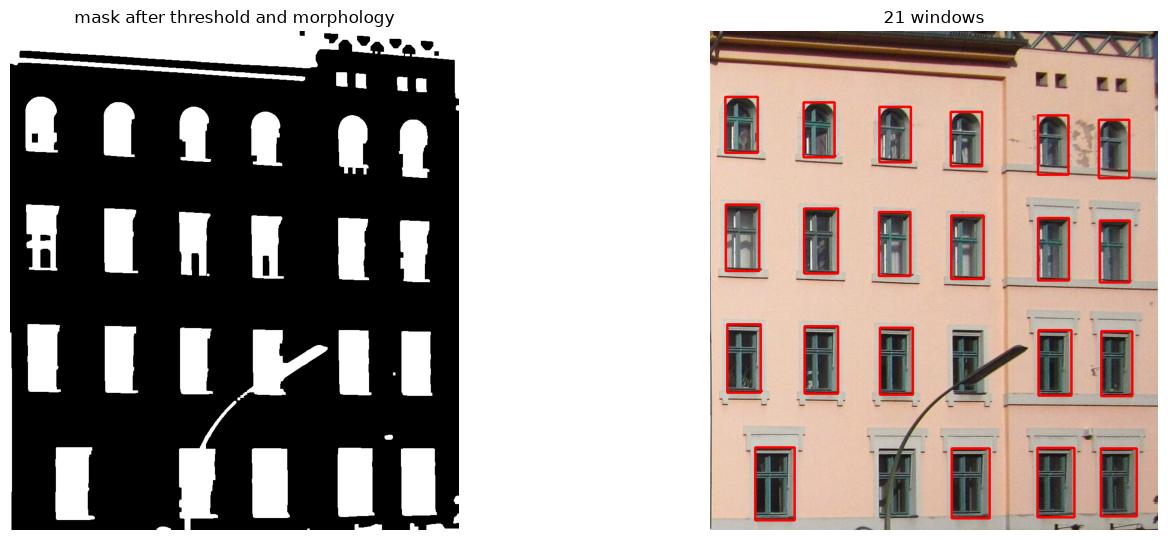

In [20]:
def find_windows(image, min_box=1500, max_box=20000, aspect=(1.2, 2.6), min_extent=0.6):
    gray = cv2.GaussianBlur(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    _, dark = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    dark = cv2.morphologyEx(dark, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    contours, _ = cv2.findContours(dark, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    windows = []
    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)
        extent = cv2.contourArea(contour) / (w * h)
        if min_box < w * h < max_box and aspect[0] < h / w < aspect[1] and extent > min_extent:
            windows.append((x, y, w, h))
    return windows, dark


def draw_boxes(image, boxes, color=(0, 0, 255), thickness=3):
    out = image.copy()
    for x, y, w, h in boxes:
        cv2.rectangle(out, (x, y), (x + w, y + h), color, thickness)
    return out


windows, dark_mask = find_windows(elevation)
window_share = sum(w * h for _, _, w, h in windows) / (ELEVATION_W * ELEVATION_H)
print(f"{len(windows)} windows found; window boxes cover {window_share:.1%} of the elevation")
show_row([dark_mask, draw_boxes(elevation, windows)], ["mask after threshold and morphology", f"{len(windows)} windows"],
         "nb2_15_windows", height=5.5)

The rule finds **21 of the 23 windows** of the rectified wing, and the window boxes cover **19.7%** of the elevation, a first estimate of the window-to-wall ratio (WWR). The **2 missed windows** are both crossed by the **street lamp**: its dark pole joins the window to other dark shapes, so the blob is no longer a clean rectangle and the shape filter rejects it.

🤔 **Think about it:** where else would this rule fail? Open windows, reflections of the sky, curtains, shadows from balconies, dark facades with light window frames... Every new situation needs a new tweak.

# 6. Finding a known object: SIFT feature matching

Colour rules need a distinctive colour. To find a **specific object** (this machine, this sign, this facade element) in other images, we can match **local features** instead. **SIFT** (*Scale-Invariant Feature Transform*) finds distinctive **keypoints** (corners, blobs, texture) and describes each one with 128 numbers that stay similar when the object is seen bigger, smaller, rotated or in different light.

The recipe, as in the reference deliverable's robot detection:
1. Crop a **template** of the object from one frame.
2. Detect SIFT keypoints in the template and in a new frame.
3. **Match** them (brute force) and keep only clear matches with **Lowe's ratio test**: the best match must be clearly better than the second best.
4. With enough matches, fit a **homography** with RANSAC (which ignores wrong matches) and project the template's outline into the new frame.
5. **Sanity-check** the result: enough matches must agree with the homography (**inliers**), and the projected outline must be a **convex** shape of plausible size. Without this check, a handful of accidental matches can produce a wild, twisted "detection".

Template: 335 x 310 px, 784 SIFT keypoints
90 s: 53 good matches
Figure saved to figures/nb2_16_sift.png


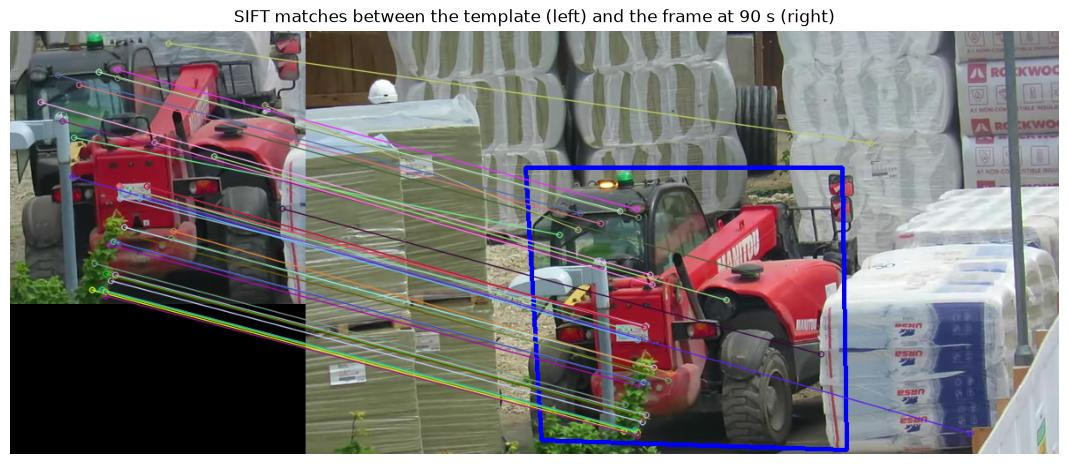

In [21]:
template = frame_telehandler[160:470, 345:680]          # the telehandler, cropped from the 60 s frame
sift = cv2.SIFT_create()
matcher = cv2.BFMatcher()
template_gray = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)
template_kp, template_desc = sift.detectAndCompute(template_gray, None)
print(f"Template: {template.shape[1]} x {template.shape[0]} px, {len(template_kp)} SIFT keypoints")


def find_template(frame, min_matches=10, min_inliers=15):
    # Return (outline in the frame or None, number of good matches, matches, frame keypoints)
    keypoints, descriptors = sift.detectAndCompute(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), None)
    if descriptors is None:
        return None, 0, [], keypoints
    good = [m for m, n in matcher.knnMatch(template_desc, descriptors, k=2) if m.distance < 0.7 * n.distance]
    if len(good) < min_matches:
        return None, len(good), good, keypoints
    src = np.float32([template_kp[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([keypoints[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    homography, inliers = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    if homography is None or inliers.sum() < min_inliers:          # too few matches agree with one geometry
        return None, len(good), good, keypoints
    h, w = template.shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    outline = cv2.perspectiveTransform(corners, homography)
    area_ratio = cv2.contourArea(outline) / (w * h)
    if not cv2.isContourConvex(np.int32(outline)) or not 0.2 < area_ratio < 5:   # twisted or absurd outline
        return None, len(good), good, keypoints
    return outline, len(good), good, keypoints


later = read_frame(90)
outline, n_good, good, frame_kp = find_template(later)
found = cv2.polylines(later.copy(), [np.int32(outline)], True, (255, 0, 0), 3)
matches_image = cv2.drawMatches(template, template_kp, found, frame_kp, good[:40], None, flags=2)
print(f"90 s: {n_good} good matches")
plt.figure(figsize=(14, 5.5))
show_image(matches_image, "SIFT matches between the template (left) and the frame at 90 s (right)")
save_fig("nb2_16_sift")
plt.show()

In [22]:
# Is the telehandler in the frame? Check every 5 seconds from 40 s to 120 s
rows = []
for t in range(40, 125, 5):
    outline, n_good, _, _ = find_template(read_frame(t))
    rows.append({"second": t, "good matches": n_good, "telehandler found": outline is not None})
pd.DataFrame(rows).set_index("second").T

second,40,45,50,55,60,65,70,75,80,85,90,95,100,105,110,115,120
good matches,9,4,3,88,748,75,58,59,59,38,53,19,26,2,4,3,4
telehandler found,False,False,False,True,True,True,True,True,True,True,True,False,False,False,False,False,False


- The template (the telehandler at 60 s) has **784** keypoints. In the frame it was cut from, 748 match, which is no surprise.
- From **55 to 90 s** the camera moves and zooms, but SIFT still finds 38–88 good matches and draws the outline in the right place.
- At **95–100 s** there are still 19–26 matches, but they no longer agree on one geometry: the machine has **turned round**, so we now see its other side, which is not in the template. The sanity check rejects them. Before 55 s and after 100 s the machine is out of view (≤ 9 matches).

💡 **Tip:** SIFT is excellent for **flat, textured** objects seen from a similar side: signs, posters, facade panels, drawings, the same object from a slightly different angle. It is the basis of photogrammetry (matching photos to build 3D models). It does not "understand" a 3D object: seen from another side, it is a different object.

# 7. Privacy: anonymising faces

Site photos and videos show **people**. Under the GDPR (and similar laws elsewhere), images of identifiable people are personal data: before sharing photos in a report, a portfolio or a public dataset, faces should be **blurred**.

OpenCV ships the classic **Haar cascade** face detector (Viola and Jones, 2001): a cascade of very fast tests on light/dark rectangle patterns typical of a frontal face (eyes darker than cheeks, the bridge of the nose lighter than the eyes…). It was the standard face detector before deep learning.

7 detections: [(834, 746, 58, 58), (542, 535, 56, 56), (665, 546, 62, 62), (932, 1228, 53, 53), (166, 1185, 63, 63), (786, 1208, 65, 65), (862, 1202, 60, 60)]
Figure saved to figures/nb2_17_faces.png


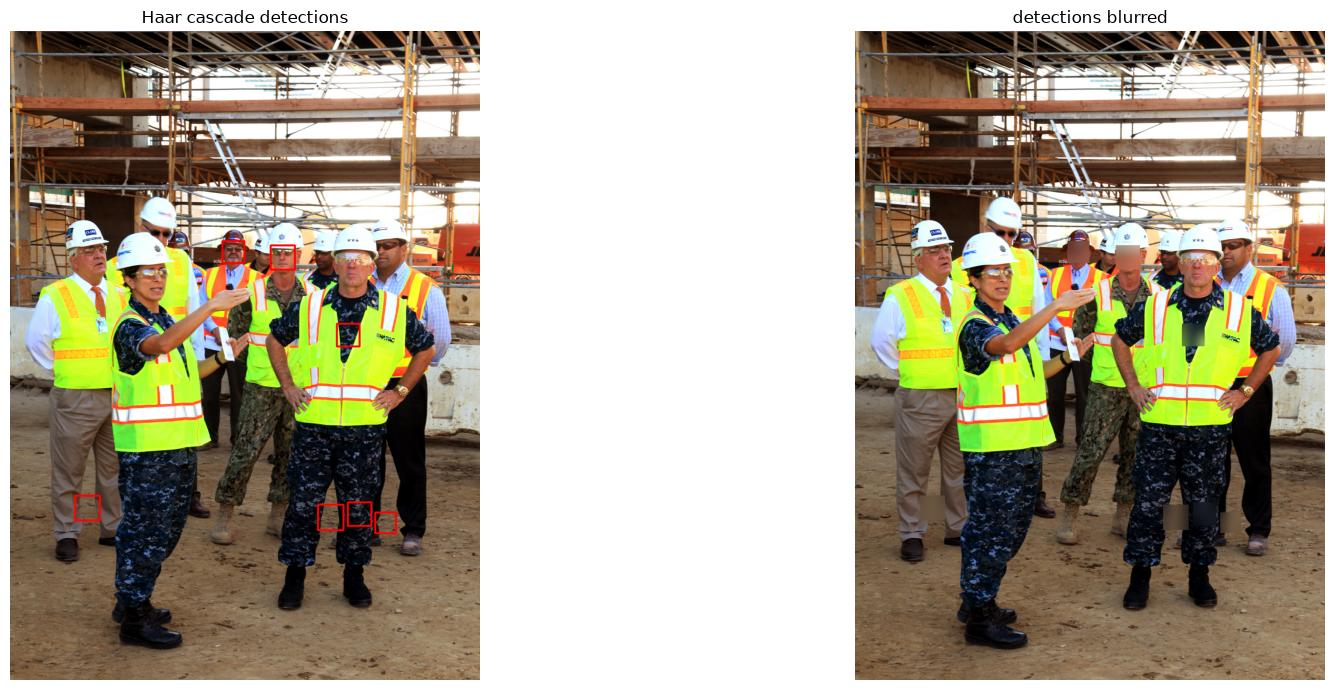

In [23]:
face_detector = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")


def find_faces(image, min_neighbors=5):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return face_detector.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=min_neighbors, minSize=(30, 30))


def blur_faces(image, faces):
    out = image.copy()
    for x, y, w, h in faces:
        region = out[y:y + h, x:x + w]
        out[y:y + h, x:x + w] = cv2.GaussianBlur(region, (0, 0), sigmaX=w / 4)   # blur strength grows with face size
    return out


faces = find_faces(site_visit)
print(f"{len(faces)} detections:", [tuple(int(v) for v in f) for f in faces])
show_row([draw_boxes(site_visit, faces), blur_faces(site_visit, faces)], ["Haar cascade detections", "detections blurred"],
         "nb2_17_faces", height=7)

The Haar cascade returns 7 detections, but only **2 are real faces** (the man with the red helmet at the back and the officer in the middle). The other 5 are **false positives** on trousers and a vest pocket: patterns of light and dark that happen to look like eyes and a nose. Meanwhile it **misses 7 of the 9 faces** in the photo: people wearing **sunglasses or safety glasses**, under **helmet** brims, or with their head **turned**.

🤔 **Think about it:** for privacy, which mistake is worse? A false positive blurs a piece of trousers (harmless). A **missed face** publishes an identifiable person (a GDPR problem). For this task we need a detector with very high **recall** (Day 2), and Haar cascades are not good enough on construction sites, where glasses and helmets are the rule.

## 7.1 A learned face detector

OpenCV also includes **YuNet**, a small **neural network** trained on thousands of annotated faces (the model file is only 0.2 MB). It is used exactly like the Haar cascade, but its "rules" were **learned from examples** instead of being designed by hand: a preview of notebook 3.

YuNet: 9 faces, confidence 0.84-0.93
Figure saved to figures/nb2_17b_faces_yunet.png


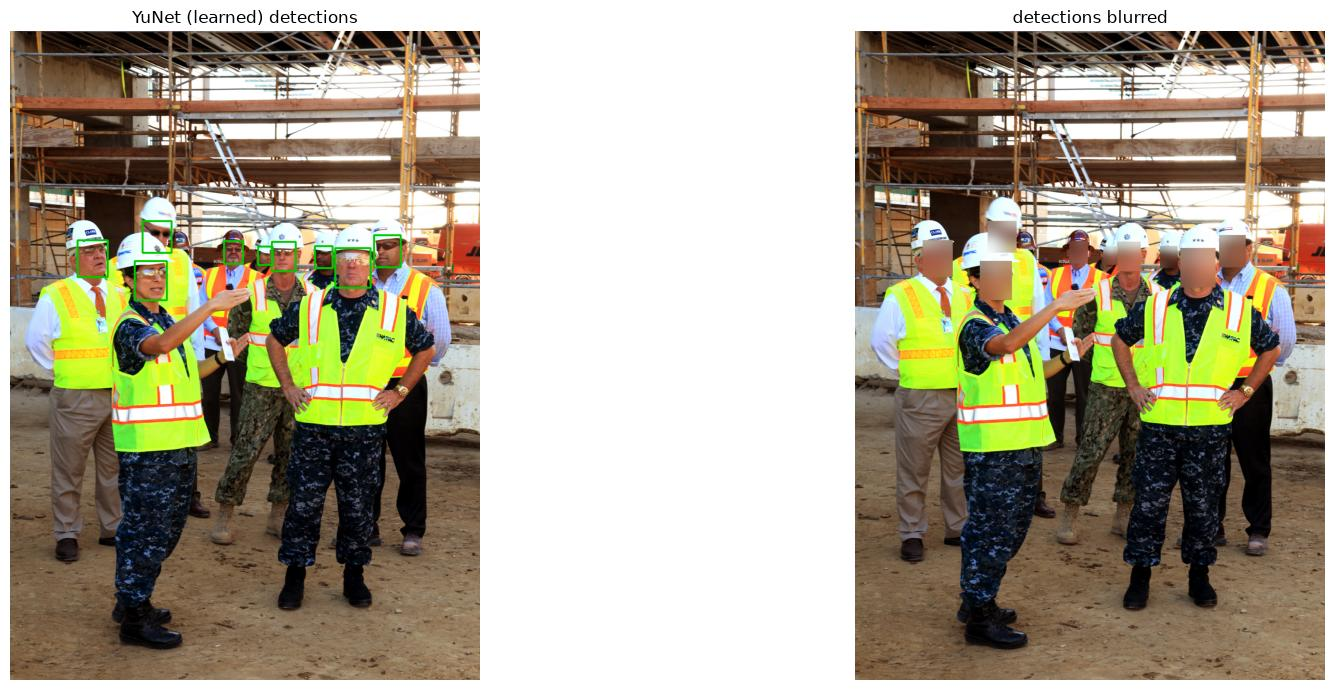

In [24]:
height, width = site_visit.shape[:2]
yunet = cv2.FaceDetectorYN.create(str(DATA_DIR / "face_detection_yunet.onnx"), "", (width, height), score_threshold=0.6)
_, detections = yunet.detect(site_visit)
learned_faces = detections[:, :4].astype(int) if detections is not None else []
print(f"YuNet: {len(learned_faces)} faces, confidence {detections[:, -1].min():.2f}-{detections[:, -1].max():.2f}")
show_row([draw_boxes(site_visit, learned_faces, color=(0, 200, 0)), blur_faces(site_visit, learned_faces)],
         ["YuNet (learned) detections", "detections blurred"], "nb2_17b_faces_yunet", height=7)

The learned detector finds **all 9 faces**, with confidences between 0.84 and 0.93, including people in sunglasses, under helmets and partly hidden behind others, and **no false positives**. Same OpenCV, same three lines of code, a very different result: the difference is that its rules were **learned** from many labelled faces.

⚠️ **Watch out:** even a good detector is not perfect. Before publishing photos of people, **check the blurred result by eye**, and blur or crop anything it missed. Small, distant faces (like the workers in our video) are hard for every detector.

# 8. A video pipeline

A video is a sequence of images, so everything above can run **frame by frame**. As in the reference deliverable, we:
1. open the video with `cv2.VideoCapture`,
2. for every frame: detect and number the **hi-vis vests**, and look for the **telehandler** with SIFT,
3. write the annotated frames to a new video with `cv2.VideoWriter`.

To keep it fast we process two short clips (the telehandler at 50–105 s and the workers at 262–300 s), and only every second frame.

Processed 1394 frames in 50 s (28 frames per second); saved data/output_rules.mp4 (56.4 MB)
Figure saved to figures/nb2_18_video_frames.png


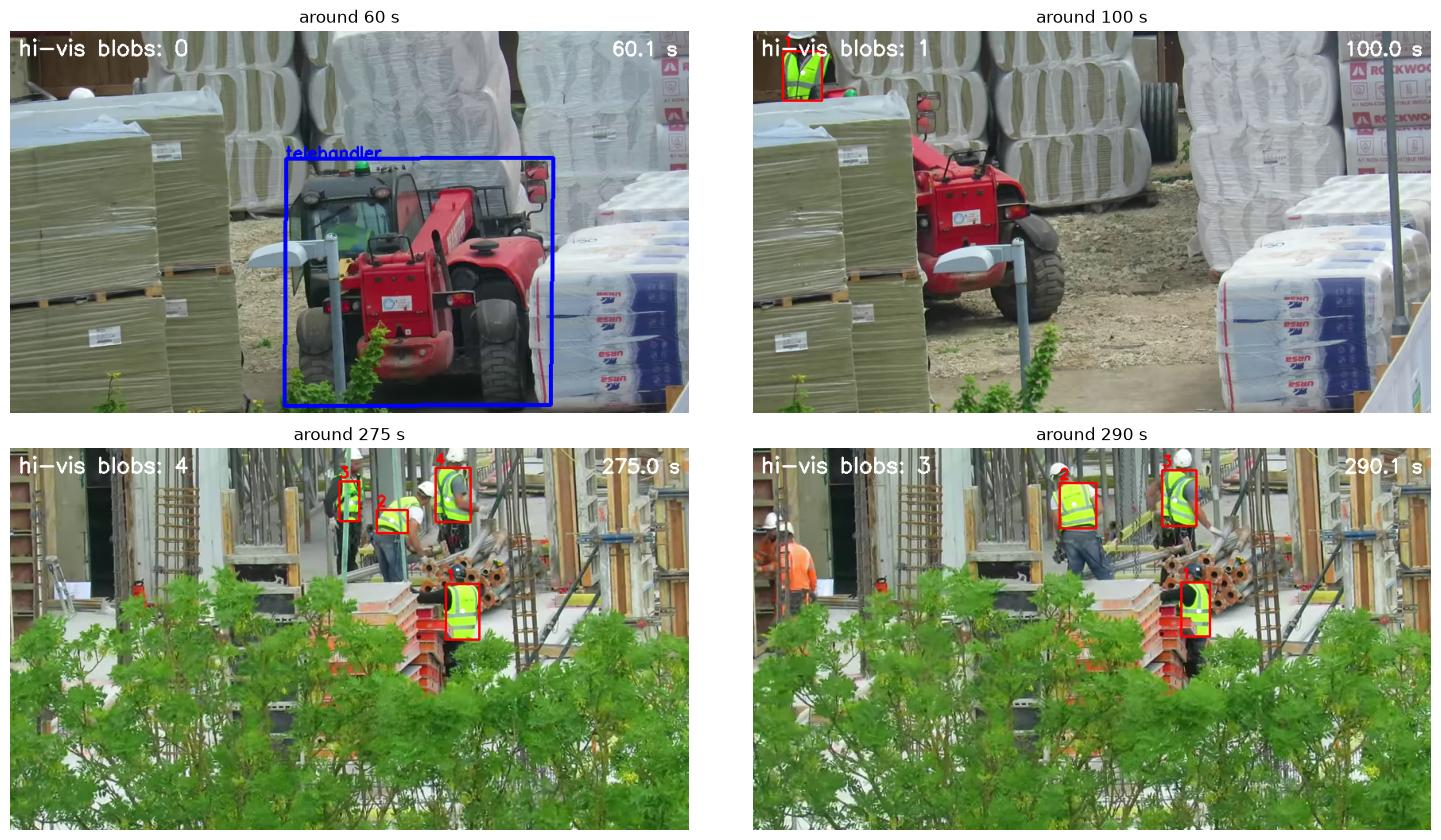

In [25]:
CLIPS = [(50, 105), (262, 300)]       # seconds
STEP = 2                              # process every 2nd frame
output_path = DATA_DIR / "output_rules.mp4"

capture = cv2.VideoCapture(str(VIDEO_PATH))
width, height = int(capture.get(3)), int(capture.get(4))
writer = cv2.VideoWriter(str(output_path), cv2.VideoWriter_fourcc(*"mp4v"), fps / STEP, (width, height))

log, examples = [], {}
start = time.time()
for clip_start, clip_end in CLIPS:
    capture.set(cv2.CAP_PROP_POS_MSEC, clip_start * 1000)
    frame_number = 0
    while True:
        ok, frame = capture.read()
        seconds = capture.get(cv2.CAP_PROP_POS_MSEC) / 1000
        if not ok or seconds > clip_end:
            break
        frame_number += 1
        if frame_number % STEP:
            continue
        vests = find_vests(frame)                                   # rule 1: colour
        annotated = draw_vests(frame, vests)
        outline, n_good, _, _ = find_template(frame)                # rule 2: SIFT
        if outline is not None:
            annotated = cv2.polylines(annotated, [np.int32(outline)], True, (255, 0, 0), 3)
            cv2.putText(annotated, "telehandler", tuple(np.int32(outline[0, 0])), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
        cv2.putText(annotated, f"{seconds:5.1f} s", (width - 110, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        writer.write(annotated)
        log.append({"second": seconds, "hi-vis blobs": len(vests), "telehandler": outline is not None})
        for t in (60, 100, 275, 290):
            if t not in examples and seconds >= t:
                examples[t] = annotated
capture.release()
writer.release()

log = pd.DataFrame(log)
print(f"Processed {len(log)} frames in {time.time() - start:.0f} s ({len(log) / (time.time() - start):.0f} frames per second); "
      f"saved {output_path} ({output_path.stat().st_size / 1e6:.1f} MB)")
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
for ax, (t, image) in zip(axes.flat, examples.items()):
    show_image(image, f"around {t} s", ax)
plt.tight_layout()
save_fig("nb2_18_video_frames")
plt.show()

Figure saved to figures/nb2_19_video_log.png


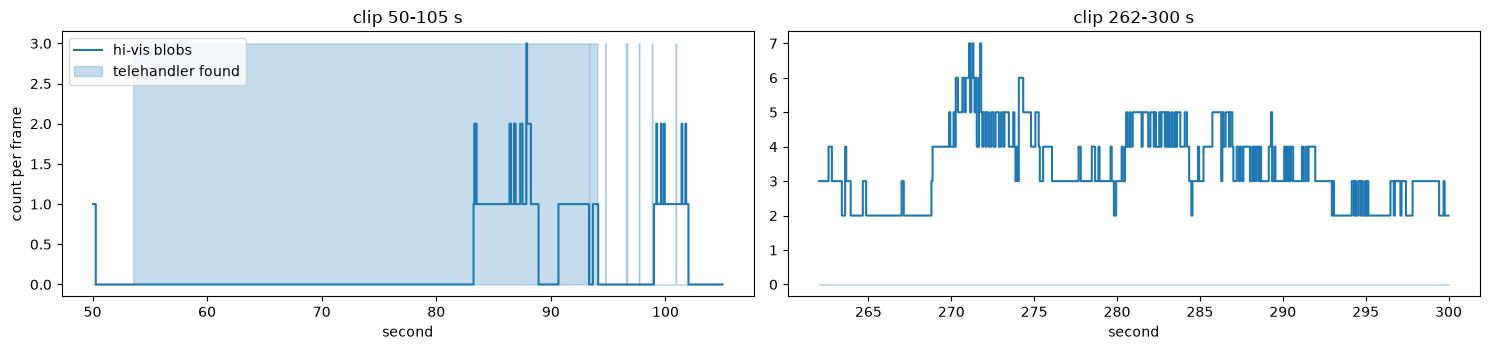

hi-vis blobs         telehandler              
               mean min max        mean    min    max
second                                               
False          0.25   0   3        0.74  False   True
True           3.39   2   7        0.00  False  False

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), sharey=False)
for ax, (clip_start, clip_end) in zip(axes, CLIPS):
    part = log[(log["second"] >= clip_start) & (log["second"] <= clip_end)]
    ax.plot(part["second"], part["hi-vis blobs"], drawstyle="steps-mid", label="hi-vis blobs")
    ax.fill_between(part["second"], 0, part["telehandler"] * part["hi-vis blobs"].max(), step="mid",
                    alpha=0.25, color="tab:blue", label="telehandler found")
    ax.set_xlabel("second")
    ax.set_title(f"clip {clip_start}-{clip_end} s")
axes[0].legend(loc="upper left")
axes[0].set_ylabel("count per frame")
plt.tight_layout()
save_fig("nb2_19_video_log")
plt.show()
log.groupby(log["second"] > 200)[["hi-vis blobs", "telehandler"]].agg(["mean", "min", "max"]).round(2)

The pipeline processed **1,394 frames** (every second frame of 93 seconds of video) in about 44 seconds, faster than real time, on a normal CPU. Reading the log:
- **Telehandler:** found in **74%** of the frames of the first clip, from about 54 s to 94 s. It is lost when the machine turns round (section 6), and never "found" in the second clip, where it is absent: **no false alarms** after the sanity check.
- **Hi-vis blobs:** in the second clip the count jumps between **2 and 7** from one frame to the next (3.4 on average), although only about four or five workers are visible. Workers move, turn, step behind each other and behind the leaves, and the blobs merge and split. In the first clip, the few blobs from 83 s onwards are a real worker who appears in the background.

💡 **Tip:** a flickering count is typical of frame-by-frame detection. Real systems smooth it over time (e.g. the median over one second) or **track** objects across frames, so that each worker keeps the same ID. Ultralytics YOLO has tracking built in (notebook 3).

⚠️ **Watch out:** the output video is about 56 MB. Do not commit videos to GitHub: keep them in `data/` (ignored), or share them on a video platform.

# 9. The limits of rules

Every rule in this notebook was tuned on **one** image or one clip. What happens when we apply the window rule, tuned on the rectified Berlin facade, to the Milan facade?

Milan: 2 'windows' found (the facade has 8 windows and 1 shuttered opening)
Figure saved to figures/nb2_20_limits.png


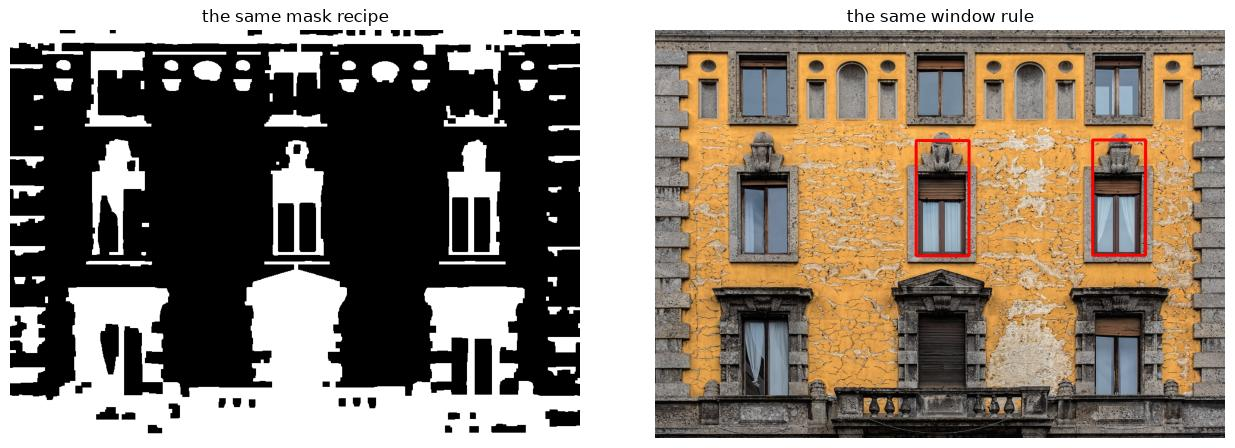

In [27]:
milan_small = cv2.resize(milan, None, fx=0.5, fy=0.5)          # a similar scale to the Berlin elevation
milan_windows, milan_mask = find_windows(milan_small)
print(f"Milan: {len(milan_windows)} 'windows' found (the facade has 8 windows and 1 shuttered opening)")
show_row([milan_mask, draw_boxes(milan_small, milan_windows)], ["the same mask recipe", "the same window rule"],
         "nb2_20_limits", height=4.5)

The same rule finds only **2 of the 8 windows** in Milan, and both boxes are too tall (they include the stone ornament above the window). The mask shows why: on this facade the **stone frames, cornices and the rusticated corners are as dark as the glass**, so windows merge with their frames into large irregular blobs that fail the shape test, while the plaster cracks add noise. The rule was not wrong; it was written for **another building**.

To make it work here we would need new thresholds, perhaps a colour rule for the yellow plaster, perhaps different shape limits... and then it would fail on the next facade. This is the fundamental limit of hand-written rules: **they do not generalise**. A learned model sees thousands of examples and learns what makes a window a window, whatever the facade. That is notebook 3.

# 10. Summary

| Task | OpenCV tools | Section |
|---|---|---|
| Resize, rotate, crop, fix exposure | `resize`, `rotate`, `warpAffine`, slicing, `equalizeHist`, CLAHE | 1 |
| Separate objects from background | `threshold` (global, Otsu, adaptive), `inRange` on HSV | 2, 4 |
| Find outlines and lines | `Canny`, Sobel kernels | 2, 3 |
| Remove noise | Gaussian, **median** (salt and pepper), **bilateral** (keeps edges) | 3 |
| Clean masks | Morphology: **opening** (specks), **closing** (holes) | 4 |
| Count and measure objects | `findContours`, `contourArea`, `moments`, `boundingRect`, `minAreaRect` | 4, 5 |
| Rectify a facade | `getPerspectiveTransform`, `warpPerspective` | 5 |
| Find a specific known object | SIFT + ratio test + `findHomography` (RANSAC) | 6 |
| Blur faces | Haar cascade + `GaussianBlur` (better: a deep-learning face detector) | 7 |
| Process video | `VideoCapture`, `VideoWriter` | 8 |

**When are rules enough?** When the scene is **controlled** (fixed camera, constant light, distinctive colours or shapes): inspection stations, scanned documents, rectified facades, a monitoring camera on one site. **When do you need learning?** When objects vary in appearance, light changes, objects overlap, or the "rule" is hard to put into words, such as "a person **without** a helmet". That is notebook 3.

# 11. Your turn

**Exercise 1 – Orange hi-vis.** Some workers wear **orange** hi-vis (see the left edge of the frame at 300 s). Find an HSV range for orange (use the chart in section 4.1), combine it with the yellow mask, and count the vests again. What new false detections appear?

**Exercise 2 – Window-to-wall ratio.** On the rectified elevation of section 5, compute the window area as a share of the facade area, using only the detected windows. Then estimate how much the 2 missed windows would add. How reliable is this estimate for an energy model?

**Exercise 3 – Your own template.** Crop a different object from one of the video frames (a sign, the concrete skip, a pallet) and use `find_template` to find it in other frames. Which objects work well with SIFT, and which do not? (Hint: think about texture.)

In [28]:
# Your code here

# 12. Conclusions and next steps

### Key findings
- An image is an **array** (height × width × 3, values 0–255) stored as **BGR** in OpenCV. Every operation in this notebook is arithmetic on that array.
- **Filtering is convolution:** a small kernel slid over the image. The same operation, with **learned** kernels, is the core of the networks in notebook 3.
- **Colour rules** in HSV plus morphology and contours found hi-vis vests in the site video, but counted **blobs, not workers**: merged pairs, split vests, missed orange vests, and a count that jumped between 2 and 7 from frame to frame.
- **Perspective correction** turned a street photo into an elevation where a simple rule found **21 of 23 windows** (window boxes: 19.7% of the facade). The **same rule** found only **2 of 8** windows on the Milan facade.
- **SIFT** tracked a known machine through camera moves (55–90 s) without false alarms, once the homography was sanity-checked, but lost it when it turned round.
- For **privacy**, the classic Haar cascade found 2 of 9 faces plus 5 false hits; OpenCV's small **learned** detector (YuNet) found all 9 with no false hits.

### Limitations
- Every threshold here was **tuned by hand on our images**; with other images, lighting or cameras they need retuning.
- Our window count and WWR come from **one wing** of **one** building, rectified by hand from 4 clicked points.
- The colour and SIFT detections were checked by eye, not against labelled ground truth: in notebook 3 we measure detection quality properly (precision, recall, mAP).

### Next: notebook 3
Rules need a human to describe the object. In **notebook 3** a neural network **learns** to detect helmets, vests, people and machinery from thousands of labelled site photos (**YOLO**), and a foundation model outlines any object we point at (**SAM**). We will run it on the **same video** and compare.

### References
- OpenCV documentation: [OpenCV-Python tutorials](https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html)
- Szeliski, R. (2022), *Computer Vision: Algorithms and Applications* (2nd ed.), free online at [szeliski.org/Book](https://szeliski.org/Book/)
- Lowe, D. G. (2004), *Distinctive image features from scale-invariant keypoints*, International Journal of Computer Vision 60 (SIFT)
- Viola, P. & Jones, M. (2001), *Rapid object detection using a boosted cascade of simple features*, CVPR (Haar cascades)
- Image and video credits: see the table in section 0.